In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
file_path = Path("../data/Online Retail.xlsx")

print("File exists:", file_path.exists())
print("File path:", file_path.resolve())

File exists: True
File path: F:\Study\work_search\portfolio\online_retail_analysis\data\Online Retail.xlsx


In [5]:
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [8]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
df.shape

(541909, 8)

In [10]:
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [12]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [13]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 541,909
Number of columns: 8


In [14]:
missing_values = df.isna().sum()

print("Missing values by column:")
print(missing_values)

Missing values by column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


In [16]:
print("Date range:")
print("From:", df["InvoiceDate"].min())
print("To:", df["InvoiceDate"].max())

print("\nQuantity statistics:")
print(df["Quantity"].describe())

print("\nUnit price statistics:")
print(df["UnitPrice"].describe())

Date range:
From: 2010-12-01 08:26:00
To: 2011-12-09 12:50:00

Quantity statistics:
count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

Unit price statistics:
count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64


In [17]:
missing_summary = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

missing_summary.sort_values(
    by="Missing %",
    ascending=False
)

,Missing values,Missing %
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [6]:
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.sort_values(
    by=["InvoiceNo", "StockCode"]
).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [19]:
print("Rows with negative quantity:", (df["Quantity"] < 0).sum())
print("Rows with zero quantity:", (df["Quantity"] == 0).sum())

print("Rows with negative price:", (df["UnitPrice"] < 0).sum())
print("Rows with zero price:", (df["UnitPrice"] == 0).sum())

Rows with negative quantity: 10624
Rows with zero quantity: 0
Rows with negative price: 2
Rows with zero price: 2515


In [20]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

print("Invoices starting with C:",
      df["InvoiceNo"].str.startswith("C").sum())

# Inspect rows with negative quantity
df.loc[df["Quantity"] < 0, [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"
]].head(10)

Invoices starting with C: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0


In [21]:
df.loc[df["UnitPrice"] < 0, [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"
]]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN


In [22]:
df.loc[df["UnitPrice"] == 0, [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"
]].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN


In [23]:
print("Missing Quantity:", df["Quantity"].isna().sum())
print("Missing UnitPrice:", df["UnitPrice"].isna().sum())

print("\nNegative quantity, C invoice:")
print(
    ((df["Quantity"] < 0) &
     df["InvoiceNo"].str.startswith("C")).sum()
)

print("\nNegative quantity, other invoices:")
print(
    ((df["Quantity"] < 0) &
     ~df["InvoiceNo"].str.startswith("C")).sum()
)

Missing Quantity: 0
Missing UnitPrice: 0

Negative quantity, C invoice:
9288

Negative quantity, other invoices:
1336


In [7]:
df_clean = df.copy()

# Calculate the transaction value
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [8]:
# Create a flag for cancellation invoices
df_clean["IsCancellation"] = (
    df_clean["InvoiceNo"].str.startswith("C")
)

# Create a flag for negative quantities
df_clean["IsNegativeQuantity"] = (
    df_clean["Quantity"] < 0
)

# Summarize transaction types
print("Cancellation invoice rows:",
      df_clean["IsCancellation"].sum())

print("Negative quantity rows:",
      df_clean["IsNegativeQuantity"].sum())

print("Negative quantity without C invoice:",
      (
          df_clean["IsNegativeQuantity"]
          & ~df_clean["IsCancellation"]
      ).sum())

Cancellation invoice rows: 9288
Negative quantity rows: 10624


TypeError: bad operand type for unary ~: 'float'

In [26]:
df_clean[[
    "InvoiceNo",
    "Quantity",
    "UnitPrice",
    "Revenue",
    "IsCancellation"
]].head(10)

,InvoiceNo,Quantity,UnitPrice,Revenue,IsCancellation
0,536365,6,2.55,15.30,False
1,536365,6,3.39,20.34,False
2,536365,8,2.75,22.00,False
3,536365,6,3.39,20.34,False
4,536365,6,3.39,20.34,False
5,536365,2,7.65,15.30,False
6,536365,6,4.25,25.50,False
7,536366,6,1.85,11.10,False
8,536366,6,1.85,11.10,False
9,536367,32,1.69,54.08,False


In [9]:
print("Rows before removing duplicates:", len(df_clean))

df_no_duplicates = df_clean.drop_duplicates()

print("Rows after removing duplicates:", len(df_no_duplicates))
print("Rows removed:", len(df_clean) - len(df_no_duplicates))

Rows before removing duplicates: 541909
Rows after removing duplicates: 536641
Rows removed: 5268


In [28]:
print(
    "Revenue before removing duplicates:",
    round(df_clean["Revenue"].sum(), 2)
)

print(
    "Revenue after removing duplicates:",
    round(df_no_duplicates["Revenue"].sum(), 2)
)

print(
    "Revenue difference:",
    round(
        df_clean["Revenue"].sum()
        - df_no_duplicates["Revenue"].sum(),
        2
    )
)

Revenue before removing duplicates: 9747747.93
Revenue after removing duplicates: 9726006.95
Revenue difference: 21740.98


In [10]:
# Create the base cleaned dataset
df_clean = df.drop_duplicates().copy()

# Calculate line-level revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Add a cancellation indicator
df_clean["IsCancellation"] = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

print("Rows in cleaned dataset:", len(df_clean))
print("Duplicate rows remaining:", df_clean.duplicated().sum())

Rows in cleaned dataset: 536641
Duplicate rows remaining: 0


In [11]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "online_retail_clean.csv"

df_clean.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())
print("File size:", round(output_path.stat().st_size / (1024 ** 2), 2), "MB")

Saved to: F:\Study\work_search\portfolio\online_retail_analysis\data\processed\online_retail_clean.csv
File size: 52.61 MB


In [12]:
print("Rows:", len(df_clean))
print("Unique invoices:", df_clean["InvoiceNo"].nunique())
print("Unique products:", df_clean["StockCode"].nunique())
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Countries:", df_clean["Country"].nunique())

Rows: 536641
Unique invoices: 25900
Unique products: 4070
Unique customers: 4372
Countries: 38


In [13]:
print("First transaction:", df_clean["InvoiceDate"].min())
print("Last transaction:", df_clean["InvoiceDate"].max())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


In [14]:
print("Total revenue:", round(df_clean["Revenue"].sum(), 2))

print(
    "Revenue from positive-quantity rows:",
    round(
        df_clean.loc[df_clean["Quantity"] > 0, "Revenue"].sum(),
        2
    )
)

print(
    "Revenue from negative-quantity rows:",
    round(
        df_clean.loc[df_clean["Quantity"] < 0, "Revenue"].sum(),
        2
    )
)

Total revenue: 9726006.95
Revenue from positive-quantity rows: 10619986.68
Revenue from negative-quantity rows: -893979.73


In [15]:
# Create monthly sales summary
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

monthly_sales = (
    df_clean[df_clean["Quantity"] > 0]
    .set_index("InvoiceDate")["Revenue"]
    .resample("MS")
    .sum()
)

monthly_sales

InvoiceDate
2010-12-01     821452.730
2011-01-01     689811.610
2011-02-01     522545.560
2011-03-01     716215.260
2011-04-01     536968.491
2011-05-01     769296.610
2011-06-01     760547.010
2011-07-01     718076.121
2011-08-01     735717.260
2011-09-01    1056435.192
2011-10-01    1151263.730
2011-11-01    1503866.780
2011-12-01     637790.330
Freq: MS, Name: Revenue, dtype: float64

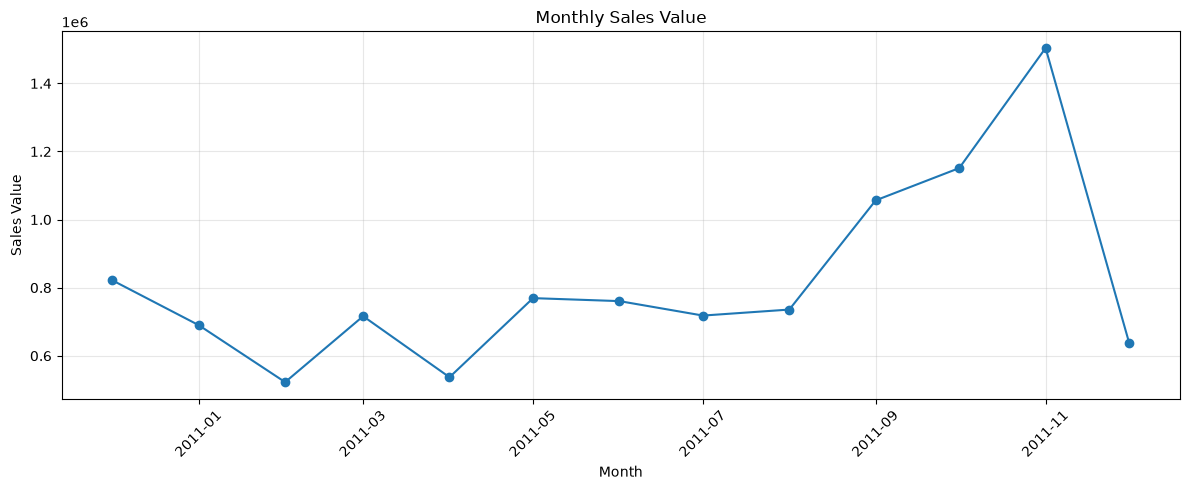

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Value")
plt.xlabel("Month")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

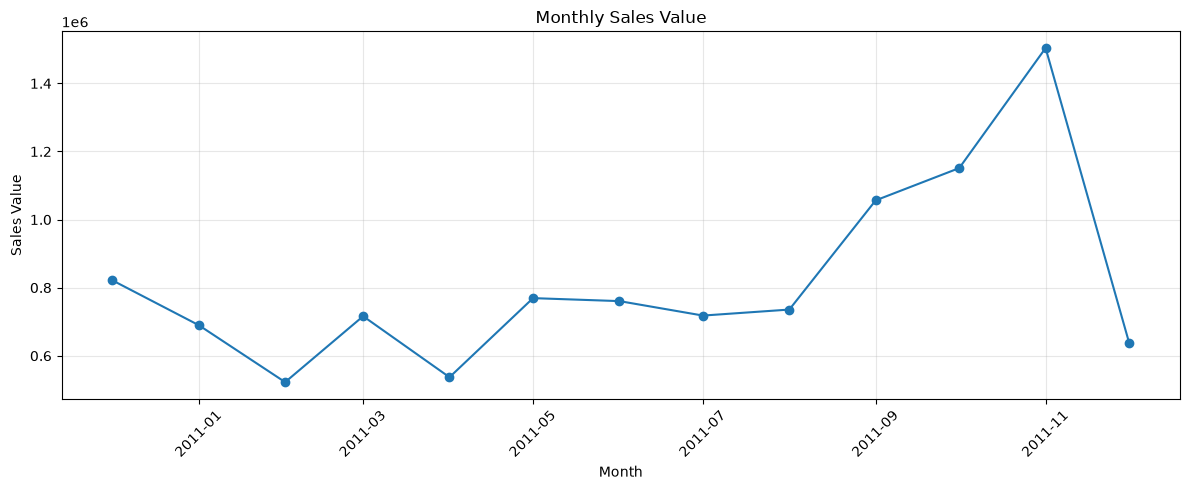

In [17]:
from pathlib import Path

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(monthly_sales.index, monthly_sales.values, marker="o")

ax.set_title("Monthly Sales Value")
ax.set_xlabel("Month")
ax.set_ylabel("Sales Value")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

fig.tight_layout()

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "monthly_sales.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [18]:
product_sales = (
    df_clean[df_clean["Quantity"] > 0]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        UnitsSold=("Quantity", "sum"),
        SalesValue=("Revenue", "sum")
    )
    .sort_values("SalesValue", ascending=False)
)

product_sales.head(10)

,,UnitsSold,SalesValue
StockCode,Description,,
DOT,DOTCOM POSTAGE,708,206248.77
22423,REGENCY CAKESTAND 3 TIER,13862,174156.54
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24
47566,PARTY BUNTING,18287,99445.23
85099B,JUMBO BAG RED RETROSPOT,48375,94159.81
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
POST,POSTAGE,3150,78101.88
M,Manual,6990,77750.27


In [19]:
# Top 10 products by units sold
top_by_quantity = product_sales.sort_values(
    "UnitsSold", ascending=False
).head(10)

top_by_quantity

,,UnitsSold,SalesValue
StockCode,Description,,
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
85099B,JUMBO BAG RED RETROSPOT,48375,94159.81
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24
22197,POPCORN HOLDER,36749,34288.67
21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
23084,RABBIT NIGHT LIGHT,30739,66870.03


In [20]:
# Top 10 products by sales value
top_by_value = product_sales.head(10)

top_by_value

,,UnitsSold,SalesValue
StockCode,Description,,
DOT,DOTCOM POSTAGE,708,206248.77
22423,REGENCY CAKESTAND 3 TIER,13862,174156.54
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24
47566,PARTY BUNTING,18287,99445.23
85099B,JUMBO BAG RED RETROSPOT,48375,94159.81
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
POST,POSTAGE,3150,78101.88
M,Manual,6990,77750.27


In [22]:
top_products = product_sales.head(10).sort_values("SalesValue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["Description"].fillna("Unknown"),
    top_products["SalesValue"]
)

plt.title("Top 10 Products by Sales Value")
plt.xlabel("Sales Value")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

KeyError: 'Description'

<Figure size 1000x600 with 0 Axes>

In [23]:
print(product_sales.columns.tolist())

['UnitsSold', 'SalesValue']


In [24]:
product_sales.head()

,,UnitsSold,SalesValue
StockCode,Description,,
DOT,DOTCOM POSTAGE,708,206248.77
22423,REGENCY CAKESTAND 3 TIER,13862,174156.54
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24
47566,PARTY BUNTING,18287,99445.23


In [25]:
product_sales = product_sales.reset_index()

print(product_sales.columns.tolist())

['StockCode', 'Description', 'UnitsSold', 'SalesValue']


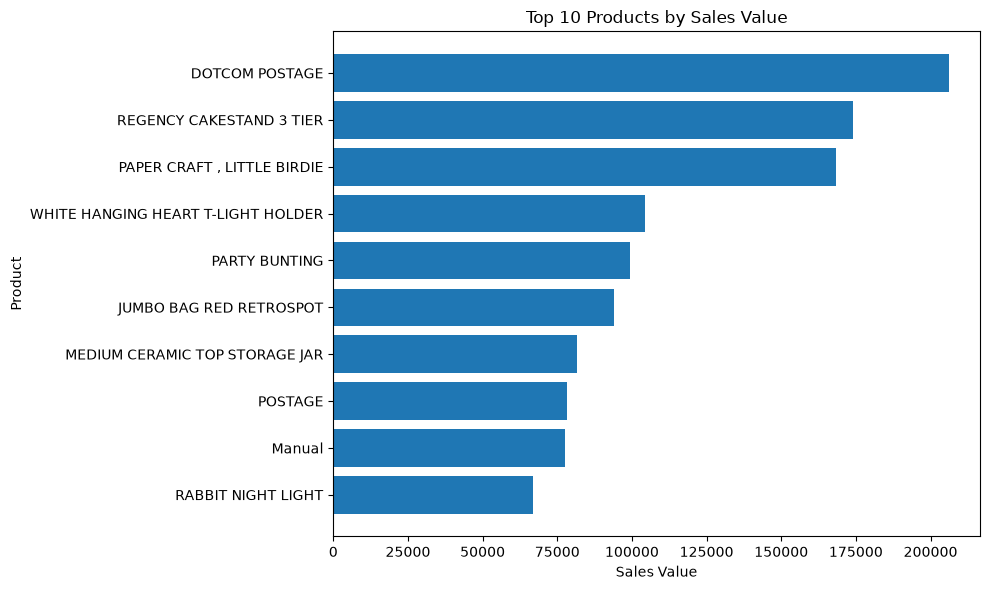

In [26]:
top_products = product_sales.head(10).sort_values("SalesValue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["Description"].fillna("Unknown"),
    top_products["SalesValue"]
)

plt.title("Top 10 Products by Sales Value")
plt.xlabel("Sales Value")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [27]:
top_by_quantity = product_sales.sort_values(
    "UnitsSold", ascending=False
).head(10)

top_by_quantity

,StockCode,Description,UnitsSold,SalesValue
2,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
145,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
5,85099B,JUMBO BAG RED RETROSPOT,48375,94159.81
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24
22,22197,POPCORN HOLDER,36749,34288.67
84,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
11,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
9,23084,RABBIT NIGHT LIGHT,30739,66870.03
115,22492,MINI PAINT SET VINTAGE,26633,16937.82


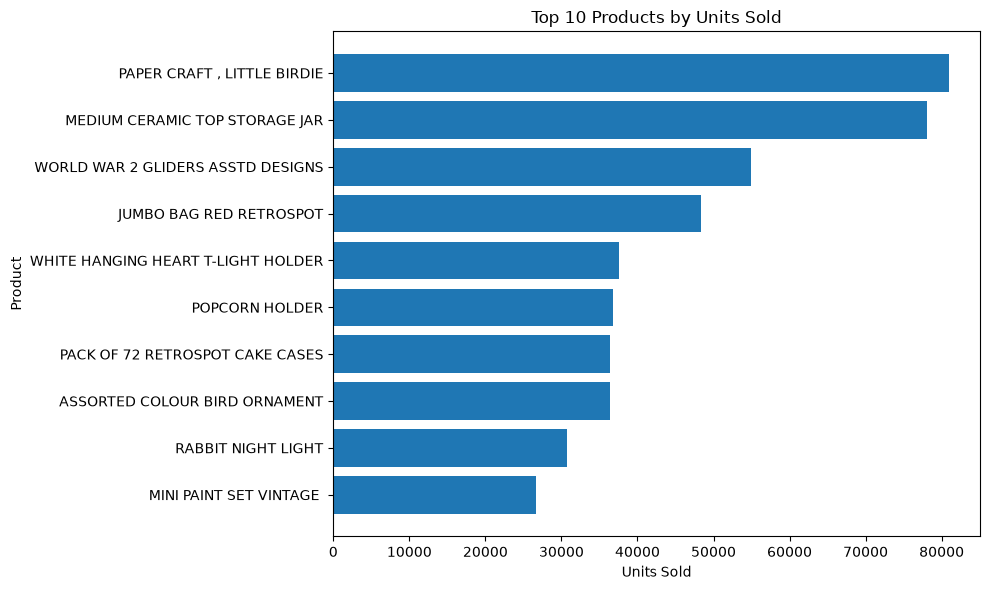

In [28]:
top_quantity = top_by_quantity.sort_values("UnitsSold")

plt.figure(figsize=(10, 6))

plt.barh(
    top_quantity["Description"].fillna("Unknown"),
    top_quantity["UnitsSold"]
)

plt.title("Top 10 Products by Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [29]:
country_sales = (
    df_clean[df_clean["Quantity"] > 0]
    .groupby("Country")
    .agg(
        UnitsSold=("Quantity", "sum"),
        SalesValue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .sort_values("SalesValue", ascending=False)
)

country_sales.head(10)

,UnitsSold,SalesValue,Orders
Country,,,
United Kingdom,4718329,8979619.974,18786
Netherlands,200937,285446.340,95
EIRE,147281,283140.520,288
Germany,119156,228678.400,457
France,112061,209625.370,392
Australia,84199,138453.810,57
Spain,27944,61558.560,90
Switzerland,30618,57067.600,54
Belgium,23237,41196.340,98


In [30]:
country_sales = country_sales.reset_index()

country_sales.head(10)

,Country,UnitsSold,SalesValue,Orders
0,United Kingdom,4718329,8979619.974,18786
1,Netherlands,200937,285446.340,95
2,EIRE,147281,283140.520,288
3,Germany,119156,228678.400,457
4,France,112061,209625.370,392
5,Australia,84199,138453.810,57
6,Spain,27944,61558.560,90
7,Switzerland,30618,57067.600,54
8,Belgium,23237,41196.340,98
9,Sweden,36078,38367.830,36


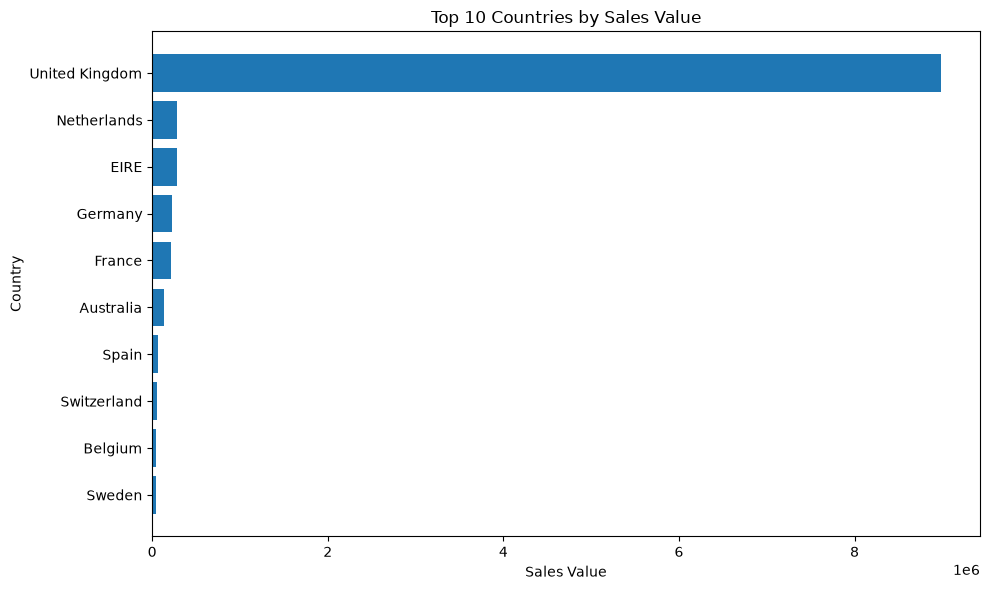

In [31]:
top_countries = country_sales.head(10).sort_values("SalesValue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries["Country"],
    top_countries["SalesValue"]
)

plt.title("Top 10 Countries by Sales Value")
plt.xlabel("Sales Value")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [32]:
total_sales = country_sales["SalesValue"].sum()

country_sales["SalesSharePct"] = (
    country_sales["SalesValue"] / total_sales * 100
)

country_sales.head(10)

,Country,UnitsSold,SalesValue,Orders,SalesSharePct
0,United Kingdom,4718329,8979619.974,18786,84.553966
1,Netherlands,200937,285446.340,95,2.687822
2,EIRE,147281,283140.520,288,2.666110
3,Germany,119156,228678.400,457,2.153283
4,France,112061,209625.370,392,1.973876
5,Australia,84199,138453.810,57,1.303710
6,Spain,27944,61558.560,90,0.579648
7,Switzerland,30618,57067.600,54,0.537360
8,Belgium,23237,41196.340,98,0.387913
9,Sweden,36078,38367.830,36,0.361279


In [33]:
country_sales[
    ["Country", "SalesValue", "SalesSharePct", "Orders"]
].head(10).round(2)

,Country,SalesValue,SalesSharePct,Orders
0,United Kingdom,8979619.97,84.55,18786
1,Netherlands,285446.34,2.69,95
2,EIRE,283140.52,2.67,288
3,Germany,228678.40,2.15,457
4,France,209625.37,1.97,392
5,Australia,138453.81,1.30,57
6,Spain,61558.56,0.58,90
7,Switzerland,57067.60,0.54,54
8,Belgium,41196.34,0.39,98
9,Sweden,38367.83,0.36,36


In [34]:
sales_data = df_clean[df_clean["Quantity"] > 0].copy()

sales_data["Month"] = (
    sales_data["InvoiceDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_sales = (
    sales_data
    .groupby("Month")
    .agg(
        SalesValue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

monthly_sales

,Month,SalesValue,Orders,UnitsSold
0,2010-12-01,821452.730,1629,361094
1,2011-01-01,689811.610,1120,397030
2,2011-02-01,522545.560,1126,286074
3,2011-03-01,716215.260,1531,384023
4,2011-04-01,536968.491,1318,311314
5,2011-05-01,769296.610,1731,398686
6,2011-06-01,760547.010,1576,393633
7,2011-07-01,718076.121,1540,405473
8,2011-08-01,735717.260,1409,424266
9,2011-09-01,1056435.192,1896,574169


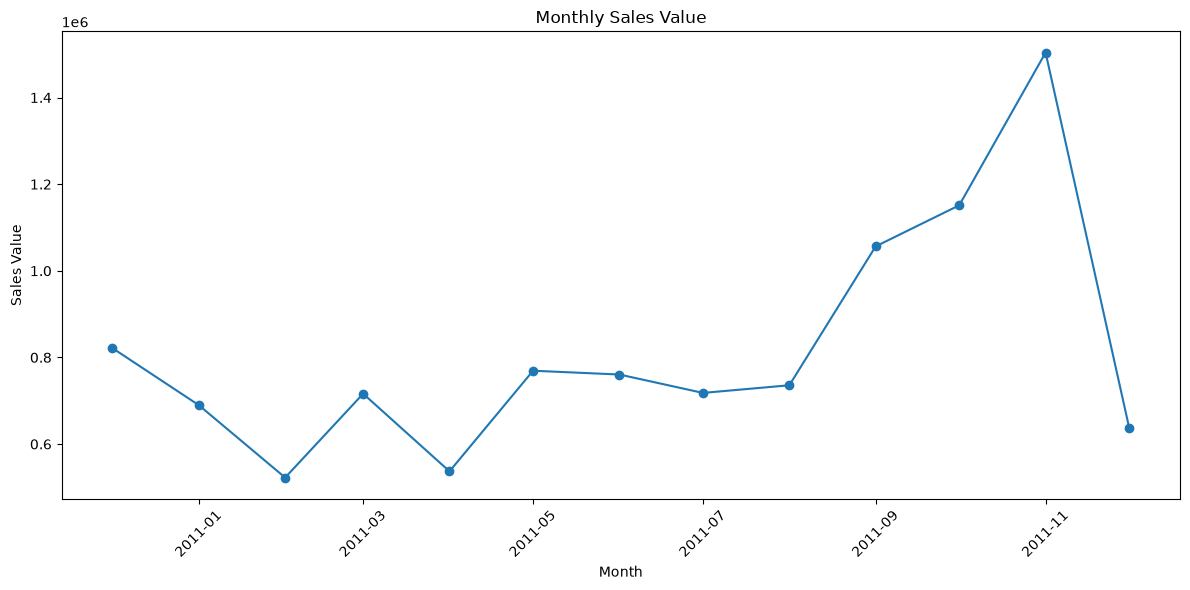

In [35]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["SalesValue"],
    marker="o"
)

plt.title("Monthly Sales Value")
plt.xlabel("Month")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
monthly_sales["SalesGrowthPct"] = (
    monthly_sales["SalesValue"].pct_change() * 100
)

monthly_sales[
    ["Month", "SalesValue", "SalesGrowthPct"]
].round(2)

C:\Users\Леонилла\AppData\Local\Temp\ipykernel_5076\3824468422.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Month,SalesValue,SalesGrowthPct
0,2010-12-01,821452.73,NaN
1,2011-01-01,689811.61,-16.03
2,2011-02-01,522545.56,-24.25
3,2011-03-01,716215.26,37.06
4,2011-04-01,536968.49,-25.03
5,2011-05-01,769296.61,43.27
6,2011-06-01,760547.01,-1.14
7,2011-07-01,718076.12,-5.58
8,2011-08-01,735717.26,2.46
9,2011-09-01,1056435.19,43.59


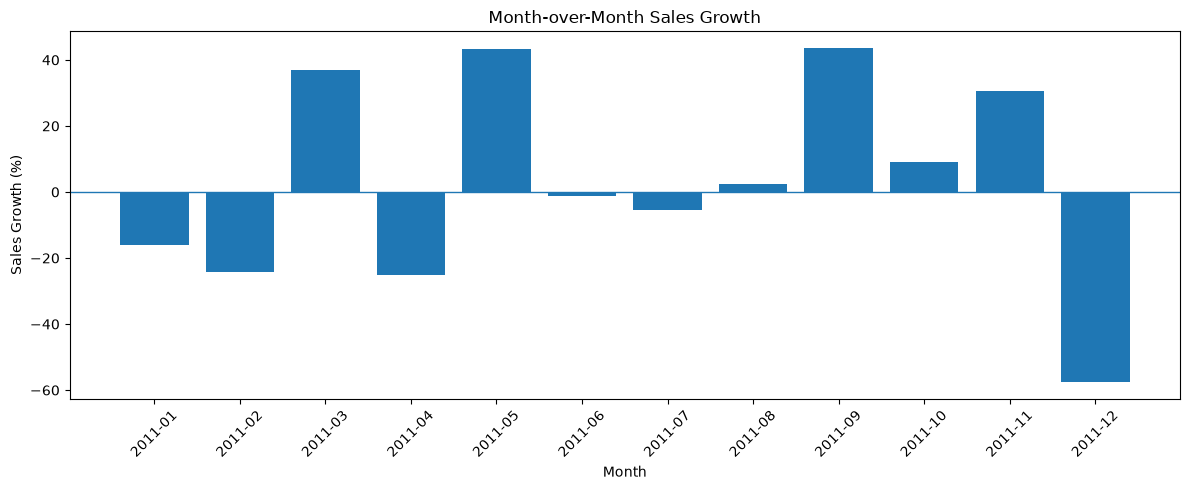

In [37]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_sales["Month"].dt.strftime("%Y-%m"),
    monthly_sales["SalesGrowthPct"]
)

plt.title("Month-over-Month Sales Growth")
plt.xlabel("Month")
plt.ylabel("Sales Growth (%)")
plt.xticks(rotation=45)
plt.axhline(y=0, linewidth=1)
plt.tight_layout()
plt.show()

In [38]:
monthly_sales["AverageOrderValue"] = (
    monthly_sales["SalesValue"] / monthly_sales["Orders"]
)

monthly_sales[
    ["Month", "SalesValue", "Orders", "AverageOrderValue"]
].round(2)

C:\Users\Леонилла\AppData\Local\Temp\ipykernel_5076\1722596611.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Month,SalesValue,Orders,AverageOrderValue
0,2010-12-01,821452.73,1629,504.27
1,2011-01-01,689811.61,1120,615.90
2,2011-02-01,522545.56,1126,464.07
3,2011-03-01,716215.26,1531,467.81
4,2011-04-01,536968.49,1318,407.41
5,2011-05-01,769296.61,1731,444.42
6,2011-06-01,760547.01,1576,482.58
7,2011-07-01,718076.12,1540,466.28
8,2011-08-01,735717.26,1409,522.16
9,2011-09-01,1056435.19,1896,557.19


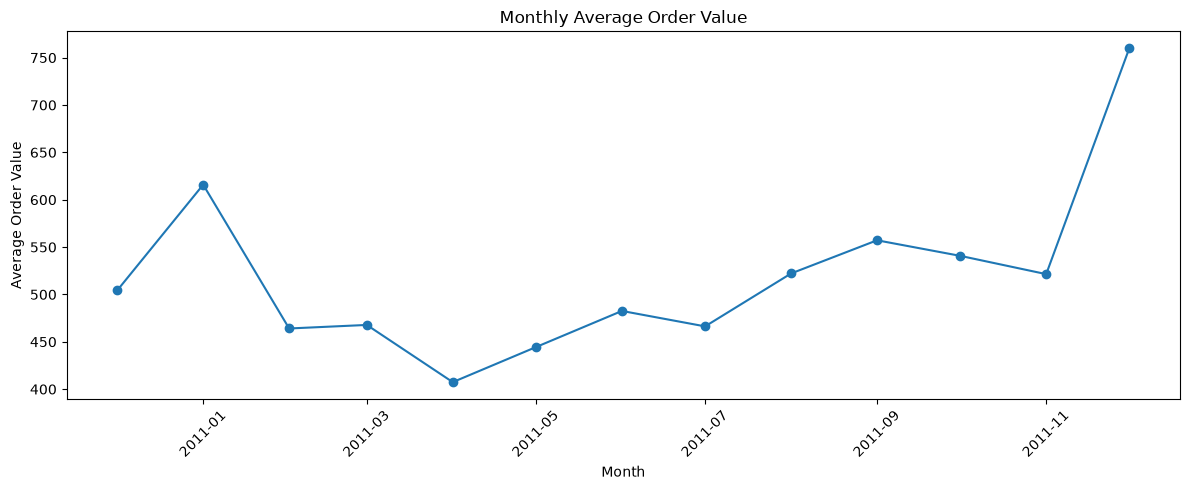

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["AverageOrderValue"],
    marker="o"
)

plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
customer_data = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["CustomerID"].notna())
].copy()

customer_sales = (
    customer_data
    .groupby("CustomerID")
    .agg(
        SalesValue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("SalesValue", ascending=False)
)

customer_sales.head(10)

,CustomerID,SalesValue,Orders,UnitsSold
1690,14646.0,280206.02,74,197491
4202,18102.0,259657.30,60,64124
3729,17450.0,194390.79,46,69973
3009,16446.0,168472.50,2,80997
1880,14911.0,143711.17,201,80490
55,12415.0,124914.53,21,77670
1334,14156.0,117210.08,55,57768
3772,17511.0,91062.38,31,64549
2703,16029.0,80850.84,63,40108
0,12346.0,77183.60,1,74215


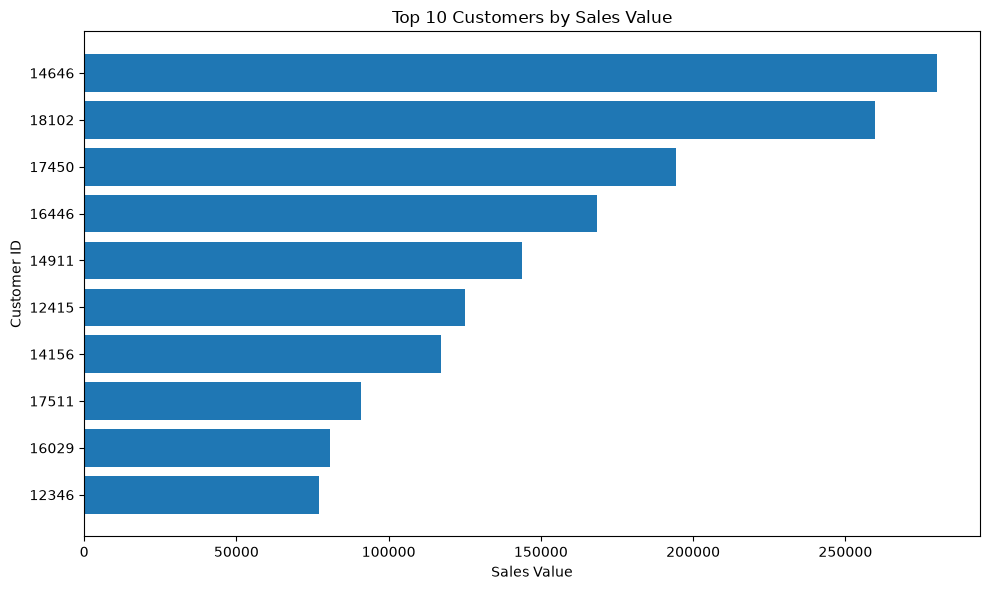

In [41]:
top_customers = (
    customer_sales.head(10)
    .sort_values("SalesValue")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_customers["CustomerID"].astype(int).astype(str),
    top_customers["SalesValue"]
)

plt.title("Top 10 Customers by Sales Value")
plt.xlabel("Sales Value")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [42]:
total_customer_sales = customer_sales["SalesValue"].sum()

top10_sales = customer_sales.head(10)["SalesValue"].sum()

top10_share = top10_sales / total_customer_sales * 100

print(f"Total sales from identified customers: {total_customer_sales:,.2f}")
print(f"Sales from top 10 customers: {top10_sales:,.2f}")
print(f"Top 10 customer share: {top10_share:.2f}%")

Total sales from identified customers: 8,887,208.89
Sales from top 10 customers: 1,537,659.21
Top 10 customer share: 17.30%


In [43]:
customer_sales.head(10).round(2)

,CustomerID,SalesValue,Orders,UnitsSold
1690,14646.0,280206.02,74,197491
4202,18102.0,259657.30,60,64124
3729,17450.0,194390.79,46,69973
3009,16446.0,168472.50,2,80997
1880,14911.0,143711.17,201,80490
55,12415.0,124914.53,21,77670
1334,14156.0,117210.08,55,57768
3772,17511.0,91062.38,31,64549
2703,16029.0,80850.84,63,40108
0,12346.0,77183.60,1,74215


In [44]:
customer_sales_sorted = customer_sales.sort_values(
    "SalesValue", ascending=False
)

total_customer_sales = customer_sales_sorted["SalesValue"].sum()

for n in [1, 5, 10, 20]:
    top_n_sales = customer_sales_sorted.head(n)["SalesValue"].sum()
    share = top_n_sales / total_customer_sales * 100

    print(f"Top {n} customers: {share:.2f}%")

Top 1 customers: 3.15%
Top 5 customers: 11.77%
Top 10 customers: 17.30%
Top 20 customers: 23.91%


In [45]:
rfm_data = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["CustomerID"].notna())
].copy()

snapshot_date = (
    rfm_data["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = (
    rfm_data
    .groupby("CustomerID")
    .agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

rfm["Recency"] = (
    snapshot_date - rfm["LastPurchase"]
).dt.days

rfm = rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary"]
]

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,18,1,1757.55
4,12350.0,310,1,334.40


In [46]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,325,1,77183.60,1,1,4
1,12347.0,2,7,4310.00,4,4,4
2,12348.0,75,4,1797.24,2,3,4
3,12349.0,18,1,1757.55,3,1,4
4,12350.0,310,1,334.40,1,1,2


In [47]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,325,1,77183.60,1,1,4,114
1,12347.0,2,7,4310.00,4,4,4,444
2,12348.0,75,4,1797.24,2,3,4,234
3,12349.0,18,1,1757.55,3,1,4,314
4,12350.0,310,1,334.40,1,1,2,112


In [48]:
rfm["RFM_Score"].value_counts().head(10)

RFM_Score
444    476
111    300
344    224
121    187
112    173
333    164
233    158
211    148
122    130
433    126
Name: count, dtype: int64

In [49]:
def segment_customer(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "Best Customers"

    elif row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "Loyal Customers"

    elif row["R_Score"] >= 3:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and (row["F_Score"] >= 3 or row["M_Score"] >= 3):
        return "At Risk"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2 and row["M_Score"] <= 2:
        return "Hibernating"

    else:
        return "Other Customers"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

rfm["Segment"].value_counts()

Segment
Best Customers      1312
Hibernating         1245
Recent Customers     858
At Risk              470
Loyal Customers      454
Name: count, dtype: int64

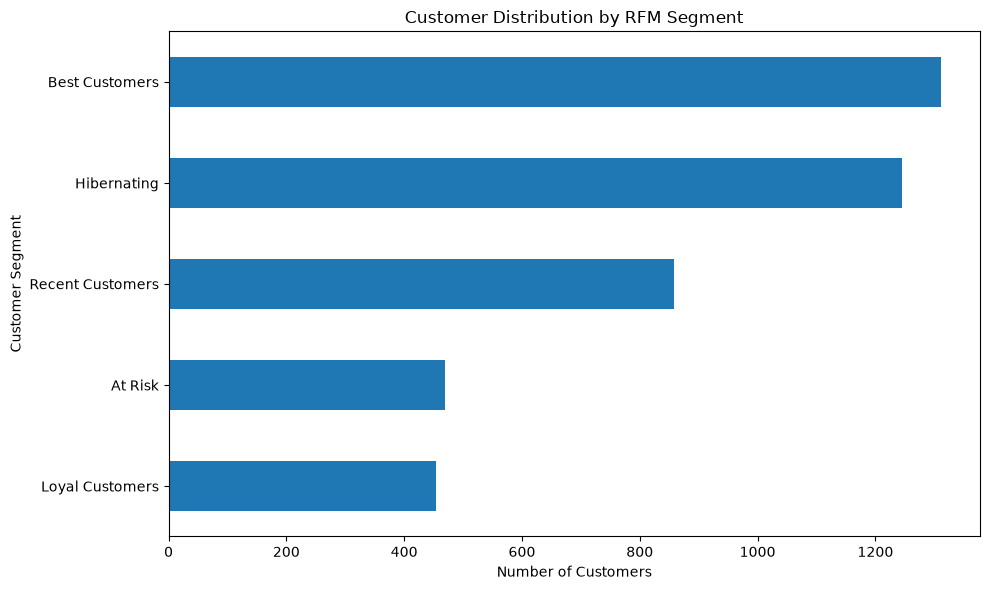

In [50]:
import matplotlib.pyplot as plt

segment_counts = (
    rfm["Segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

segment_counts.plot(
    kind="barh"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [51]:
segment_analysis = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "nunique"),
        SalesValue=("Monetary", "sum"),
        AvgSalesPerCustomer=("Monetary", "mean"),
        AvgOrders=("Frequency", "mean")
    )
    .sort_values("SalesValue", ascending=False)
    .reset_index()
)

segment_analysis

,Segment,Customers,SalesValue,AvgSalesPerCustomer,AvgOrders
0,Best Customers,1312,6477238.541,4936.919620,9.407774
1,Loyal Customers,454,967237.350,2130.478744,4.682819
2,Recent Customers,858,586025.420,683.013310,1.824009
3,At Risk,470,502957.412,1070.122153,2.178723
4,Hibernating,1245,353750.171,284.136684,1.187149


In [52]:
segment_analysis["SalesSharePct"] = (
    segment_analysis["SalesValue"]
    / segment_analysis["SalesValue"].sum()
    * 100
).round(2)

segment_analysis["CustomerSharePct"] = (
    segment_analysis["Customers"]
    / segment_analysis["Customers"].sum()
    * 100
).round(2)

segment_analysis

,Segment,Customers,SalesValue,AvgSalesPerCustomer,AvgOrders,SalesSharePct,CustomerSharePct
0,Best Customers,1312,6477238.541,4936.919620,9.407774,72.88,30.24
1,Loyal Customers,454,967237.350,2130.478744,4.682819,10.88,10.46
2,Recent Customers,858,586025.420,683.013310,1.824009,6.59,19.77
3,At Risk,470,502957.412,1070.122153,2.178723,5.66,10.83
4,Hibernating,1245,353750.171,284.136684,1.187149,3.98,28.69


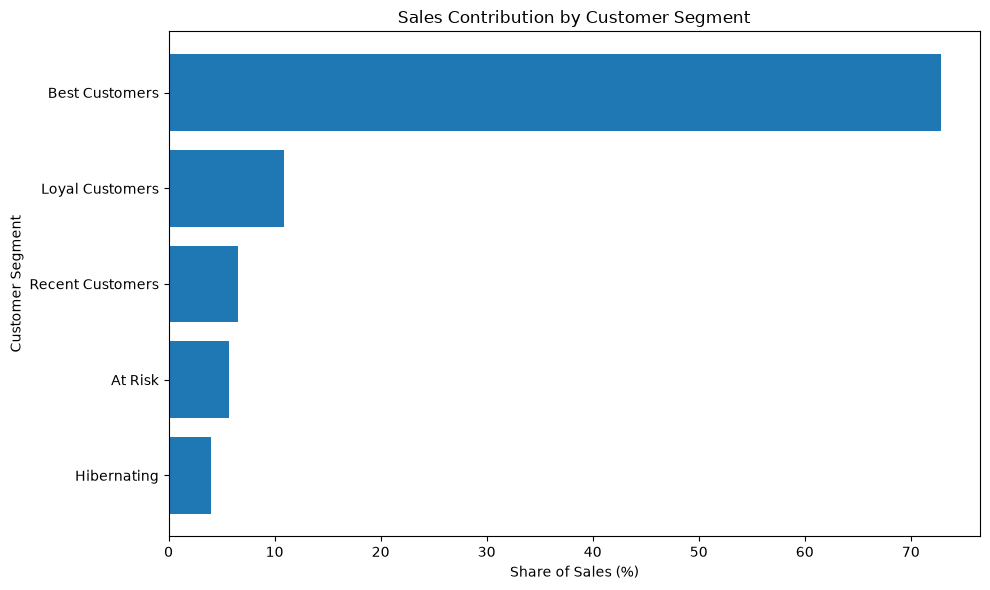

<Figure size 640x480 with 0 Axes>

In [ ]:
sales_share = segment_analysis.sort_values(
    "SalesSharePct",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    sales_share["Segment"],
    sales_share["SalesSharePct"]
)

plt.title("Sales Contribution by Customer Segment")
plt.xlabel("Share of Sales (%)")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()


In [56]:
from pathlib import Path

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "rfm_sales_share.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

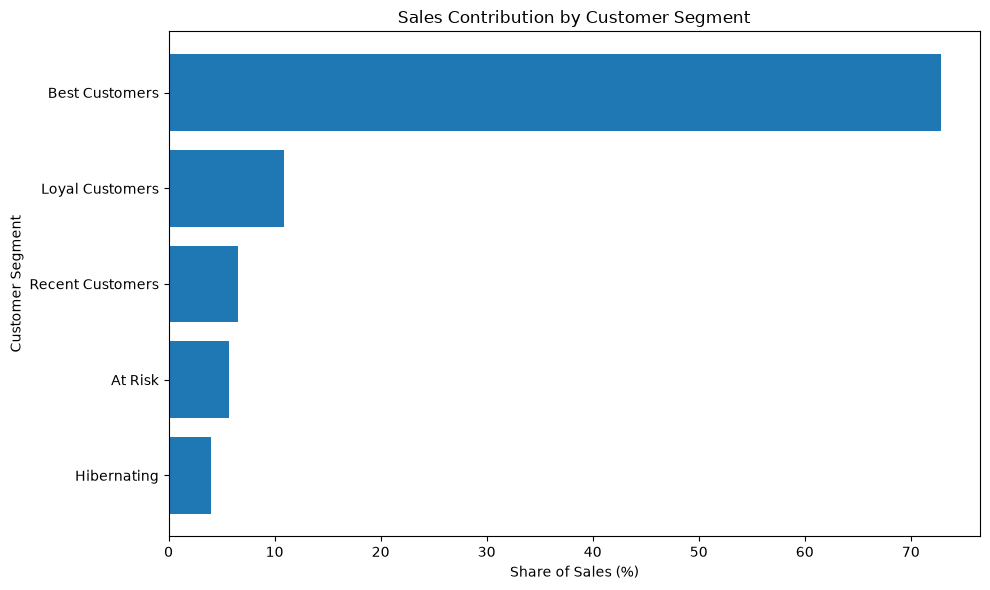

In [59]:
from pathlib import Path
import matplotlib.pyplot as plt

# Папка для сохранения графиков
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Подготовка данных
sales_share = segment_analysis.sort_values(
    "SalesSharePct",
    ascending=True
)

# Создание графика
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    sales_share["Segment"],
    sales_share["SalesSharePct"]
)

ax.set_title("Sales Contribution by Customer Segment")
ax.set_xlabel("Share of Sales (%)")
ax.set_ylabel("Customer Segment")

fig.tight_layout()

# Сохранение именно этой фигуры
fig.savefig(
    figures_dir / "rfm_sales_share.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

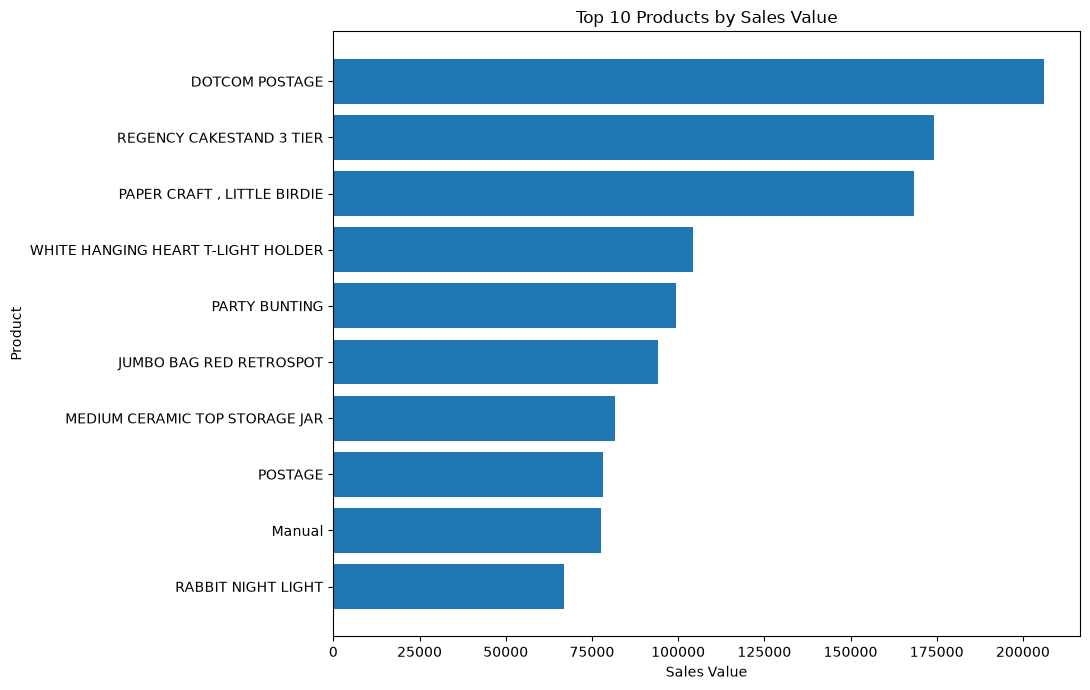

In [61]:
top_products = (
    product_sales
    .sort_values("SalesValue", ascending=False)
    .head(10)
    .sort_values("SalesValue", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_products["Description"],
    top_products["SalesValue"]
)

ax.set_title("Top 10 Products by Sales Value")
ax.set_xlabel("Sales Value")
ax.set_ylabel("Product")

fig.tight_layout()

fig.savefig(
    figures_dir / "top_products_by_sales.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

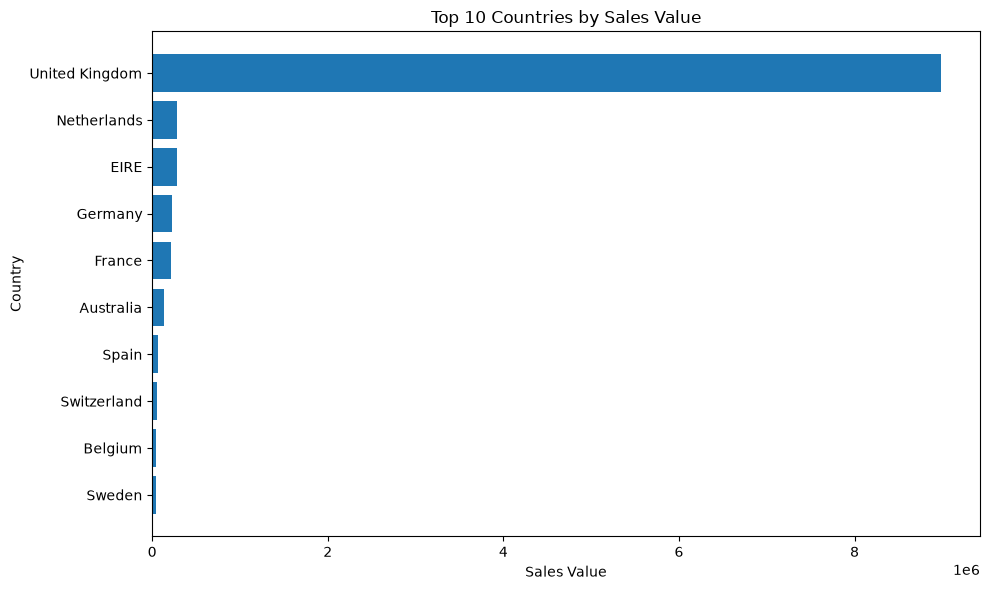

In [62]:
top_countries = (
    country_sales
    .sort_values("SalesValue", ascending=False)
    .head(10)
    .sort_values("SalesValue", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_countries["Country"],
    top_countries["SalesValue"]
)

ax.set_title("Top 10 Countries by Sales Value")
ax.set_xlabel("Sales Value")
ax.set_ylabel("Country")

fig.tight_layout()

fig.savefig(
    figures_dir / "top_countries_by_sales.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

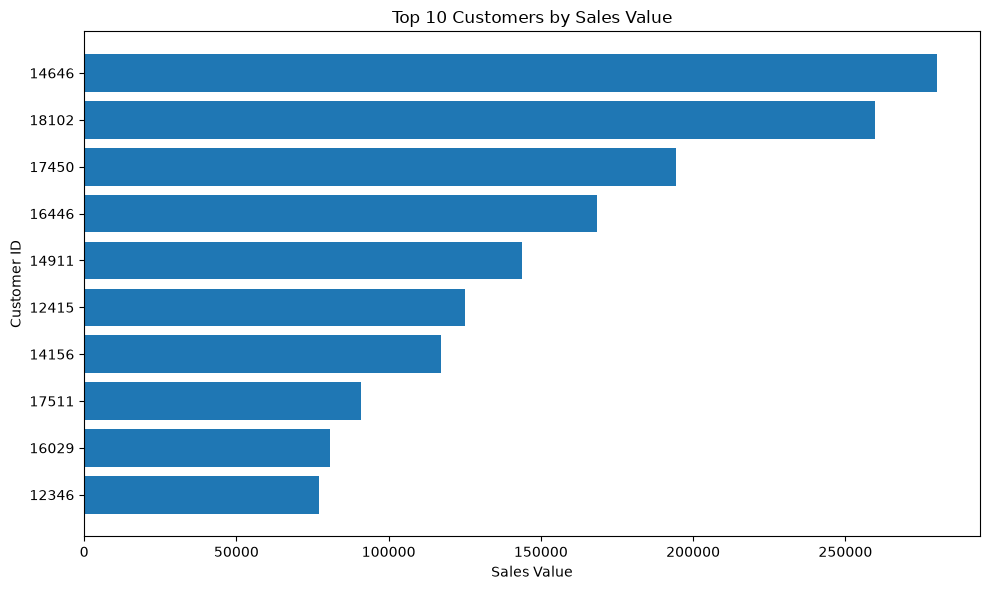

In [63]:
top_customers = (
    customer_sales
    .sort_values("SalesValue", ascending=False)
    .head(10)
    .sort_values("SalesValue", ascending=True)
    .copy()
)

top_customers["CustomerID"] = (
    top_customers["CustomerID"].astype(int).astype(str)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_customers["CustomerID"],
    top_customers["SalesValue"]
)

ax.set_title("Top 10 Customers by Sales Value")
ax.set_xlabel("Sales Value")
ax.set_ylabel("Customer ID")

fig.tight_layout()

fig.savefig(
    figures_dir / "top_customers_by_sales.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

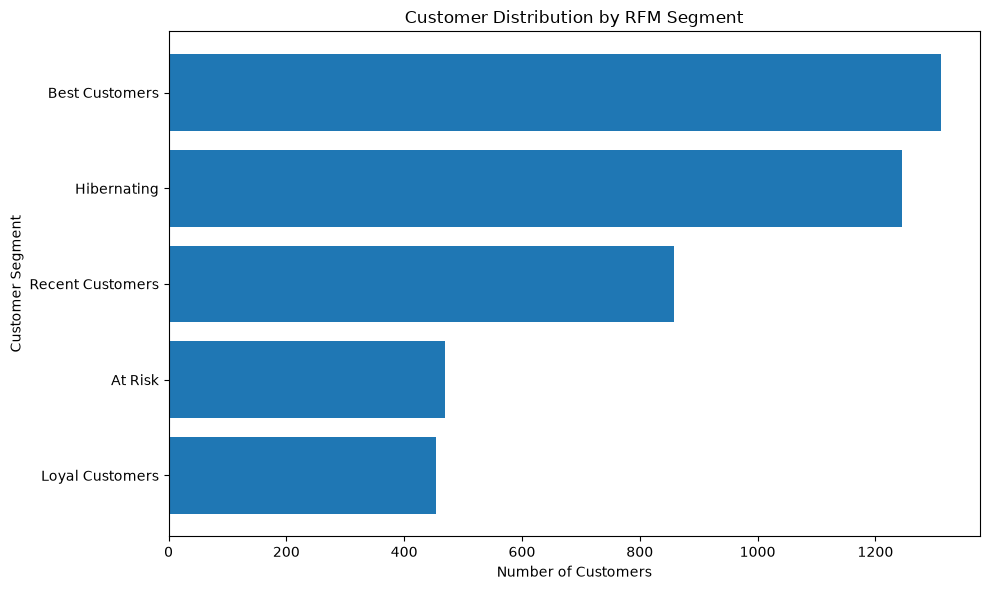

In [64]:
segment_counts = (
    rfm["Segment"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    segment_counts.index,
    segment_counts.values
)

ax.set_title("Customer Distribution by RFM Segment")
ax.set_xlabel("Number of Customers")
ax.set_ylabel("Customer Segment")

fig.tight_layout()

fig.savefig(
    figures_dir / "rfm_customer_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)